# Máquinas de Soporte Vectorial (SVM) — Implementación

**Técnicas de Machine Learning Supervisado** · Michael Lata

Este cuaderno lleva a código **todo** el informe sobre SVM. Cada sección reproduce
una parte del documento, con énfasis en el **proceso interno de los vectores de
soporte** (condiciones KKT, tipos de vector de soporte, reconstrucción de `w` y `b`,
y la regla de decisión dual).

> El *accuracy* no es el objetivo: el código busca ser **robusto** (escalado,
> `Pipeline`, `GridSearchCV` + validación cruzada y `random_state` fijo) para que
> el mejor modelo no falle.

## 0. Configuración e importaciones

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons, make_circles, load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.svm import SVC, SVR, LinearSVC
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error

import sklearn
RNG = 42                      # semilla global -> resultados reproducibles
np.random.seed(RNG)
plt.rcParams["figure.figsize"] = (6, 5)
plt.rcParams["figure.dpi"] = 110
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.0


In [2]:
def plot_svc_decision(clf, X, y, ax=None, title="", support=True, scaled_step=0.02):
    '''Dibuja frontera, margenes y vectores de soporte de un SVC ya entrenado.
    Funciona tanto si 'clf' es un SVC como si es un Pipeline(StandardScaler, SVC).'''
    if ax is None:
        _, ax = plt.subplots()
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                         np.linspace(y_min, y_max, 400))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = clf.decision_function(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z > 0, alpha=0.08, cmap="coolwarm")
    # frontera (0) y margenes (+-1)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k",
               linestyles=["--", "-", "--"], linewidths=[1, 1.6, 1])
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=30,
               edgecolors="k", linewidths=0.5, zorder=3)

    if support:
        svc = clf[-1] if isinstance(clf, Pipeline) else clf
        sv = svc.support_vectors_
        if isinstance(clf, Pipeline):           # des-escalar para dibujar en X original
            sv = clf[:-1].inverse_transform(sv)
        ax.scatter(sv[:, 0], sv[:, 1], s=160, facecolors="none",
                   edgecolors="lime", linewidths=1.8, zorder=4,
                   label=f"vectores de soporte ({len(sv)})")
        ax.legend(loc="best", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    return ax

## 1–2. Contexto e intuición: el margen máximo

Generamos dos nubes de puntos 2D **linealmente separables**. La SVM busca, de entre
todos los hiperplanos que separan las clases, el que **maximiza el margen** (la
distancia a los puntos más cercanos de cada clase).

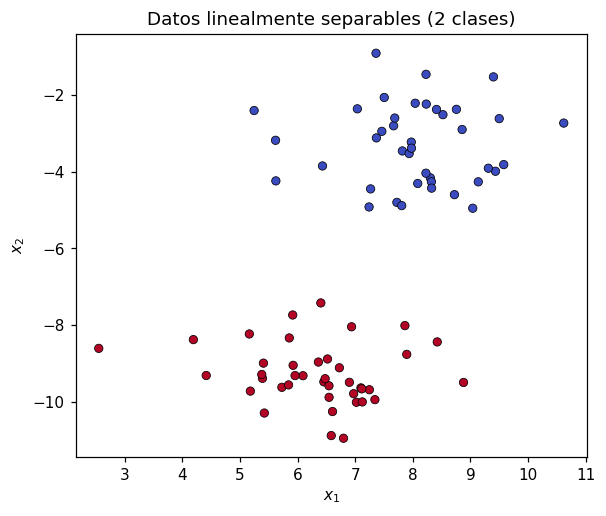

In [3]:
X_lin, y_lin = make_blobs(n_samples=80, centers=2, cluster_std=1.05,
                          random_state=6)

plt.scatter(X_lin[:, 0], X_lin[:, 1], c=y_lin, cmap="coolwarm",
            s=30, edgecolors="k", linewidths=0.5)
plt.title("Datos linealmente separables (2 clases)")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.show()

## 3.1. Margen duro (datos linealmente separables)

$$\min_{\mathbf{w},b}\ \tfrac12\|\mathbf{w}\|^2 \quad\text{s.a.}\quad y_i(\mathbf{w}\cdot\mathbf{x}_i+b)\ge 1.$$

El "margen duro" exige separación perfecta. Lo aproximamos con un `C` muy grande
(penalización casi infinita de cualquier violación). Marcamos en verde los
**vectores de soporte**: los únicos puntos que tocan el margen y definen el hiperplano.

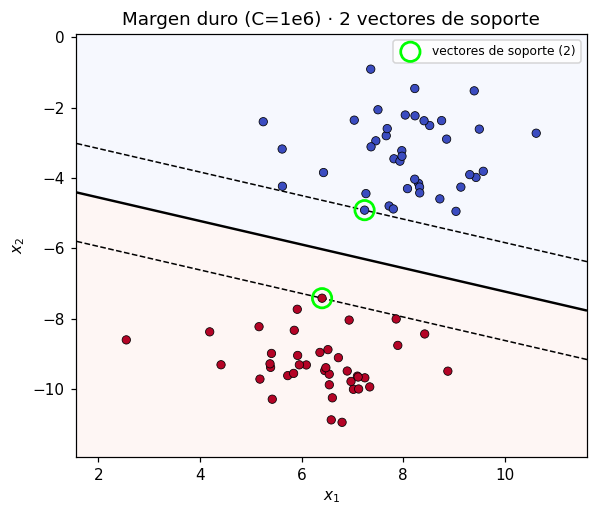

Anchura del margen = 2/||w|| = 2.640008739450898


In [4]:
hard = SVC(kernel="linear", C=1e6)      # C enorme ~ margen duro
hard.fit(X_lin, y_lin)

plot_svc_decision(hard, X_lin, y_lin,
                  title=f"Margen duro (C=1e6) · {hard.n_support_.sum()} vectores de soporte")
plt.show()
print("Anchura del margen = 2/||w|| =", 2.0 / np.linalg.norm(hard.coef_))

## 3.2. Margen blando y regularización (parámetro $C$)

$$\min_{\mathbf{w},b,\boldsymbol\xi}\ \tfrac12\|\mathbf{w}\|^2 + C\sum_i \xi_i.$$

Con datos ruidosos se permiten violaciones del margen (variables de holgura $\xi_i$).
- **$C$ alto** → margen estrecho, se ajusta al entrenamiento (riesgo de *overfitting*).
- **$C$ bajo** → margen ancho y tolerante (mejor generalización; riesgo de *underfitting*).

Observa cómo al bajar $C$ el margen se ensancha y **aumenta el número de vectores de soporte**.

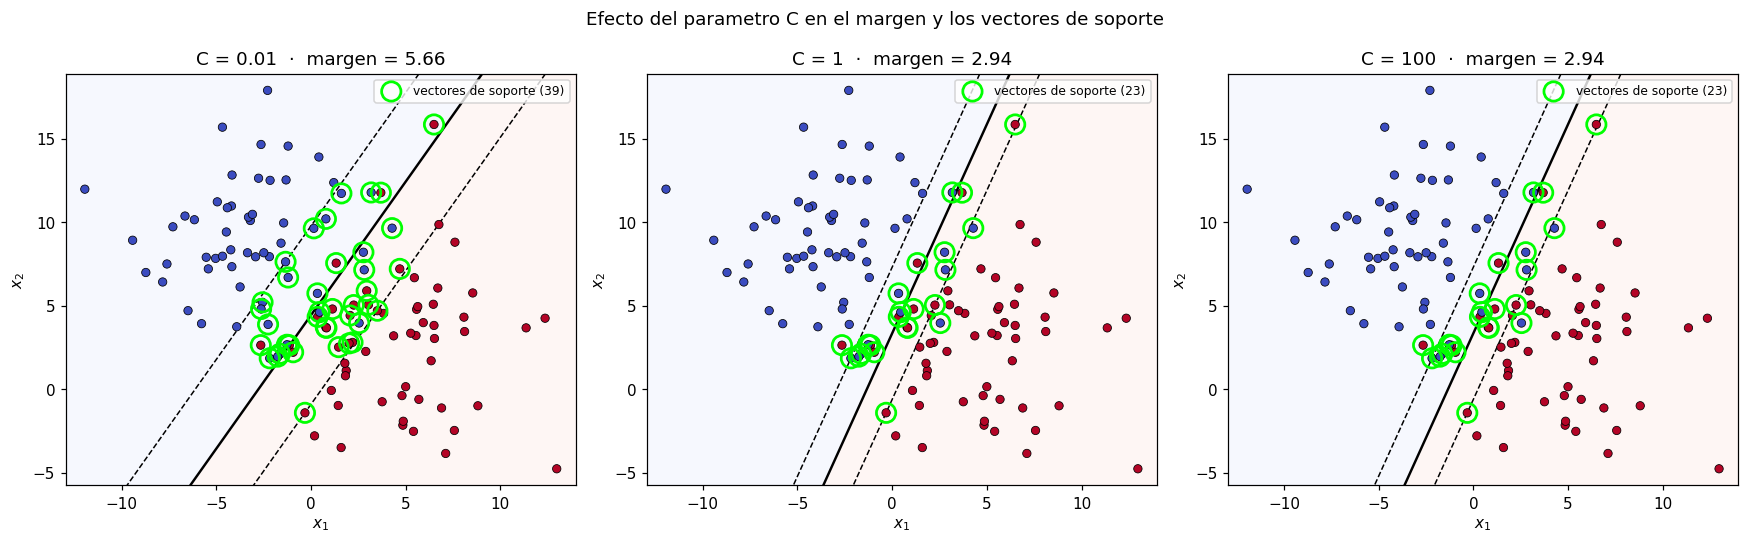

In [5]:
X_noise, y_noise = make_blobs(n_samples=120, centers=2, cluster_std=3.6,
                              random_state=RNG)   # clases solapadas a proposito

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, C in zip(axes, [0.01, 1, 100]):
    clf = SVC(kernel="linear", C=C).fit(X_noise, y_noise)
    plot_svc_decision(clf, X_noise, y_noise, ax=ax,
                      title=f"C = {C}  ·  margen = {2/np.linalg.norm(clf.coef_):.2f}")
plt.suptitle("Efecto del parametro C en el margen y los vectores de soporte")
plt.tight_layout(); plt.show()

## 3.3–3.4. Proceso interno de los vectores de soporte (el núcleo del informe)

Aquí abrimos la "caja negra" y verificamos numéricamente lo que dice el informe.

**Forma dual:** sólo las muestras con $\alpha_i > 0$ son vectores de soporte.
En `scikit-learn` los productos $\alpha_i y_i$ están en `dual_coef_`, y los vectores
de soporte en `support_vectors_`.

In [6]:
svm = SVC(kernel="linear", C=1.0).fit(X_noise, y_noise)

alpha_y = svm.dual_coef_.ravel()        # = alpha_i * y_i  (con signo)
alpha   = np.abs(alpha_y)               # alpha_i >= 0
print(f"Muestras totales : {len(X_noise)}")
print(f"Vectores de soporte (alpha>0): {len(alpha)}")
print(f"Rango de alpha : [{alpha.min():.4f}, {alpha.max():.4f}]   (C = {svm.C})")

Muestras totales : 120
Vectores de soporte (alpha>0): 23
Rango de alpha : [0.2508, 1.0000]   (C = 1.0)


### Los tres tipos de punto (condiciones KKT)

La holgura complementaria de KKT clasifica cada muestra según su $\alpha_i$:

| $\alpha_i$ | posición | rol |
|---|---|---|
| $\alpha_i = 0$ | fuera del margen, bien clasificado | **no** es vector de soporte |
| $0 < \alpha_i < C$ | justo *sobre* el margen ($\xi_i=0$) | vector de soporte **libre** (fija $b$) |
| $\alpha_i = C$ | dentro del margen / mal clasificado | vector de soporte **acotado** |

In [7]:
C = svm.C
tol = 1e-6
free    = np.sum(alpha < C - tol)       # 0 < alpha < C  -> sobre el margen
bounded = np.sum(alpha >= C - tol)      # alpha = C       -> dentro/violan margen
print(f"Vectores de soporte LIBRES   (0 < a < C): {free}")
print(f"Vectores de soporte ACOTADOS (a = C)    : {bounded}")
print(f"No-vectores de soporte (a = 0)          : {len(X_noise) - len(alpha)}")

Vectores de soporte LIBRES   (0 < a < C): 3
Vectores de soporte ACOTADOS (a = C)    : 20
No-vectores de soporte (a = 0)          : 97


### Reconstrucción de la solución desde los vectores de soporte

El informe afirma que el hiperplano **sólo depende de los vectores de soporte**:
$$\mathbf{w}=\sum_{i\in SV}\alpha_i y_i\,\mathbf{x}_i,\qquad
  b = y_k - \mathbf{w}\cdot\mathbf{x}_k\ \ (\text{con un SV libre } k).$$

Lo reconstruimos **a mano** y comprobamos que coincide con `coef_`/`intercept_`.

In [8]:
# w = sum_i (alpha_i y_i) x_i  sobre los vectores de soporte
w_manual = alpha_y @ svm.support_vectors_
print("w (manual)   :", np.round(w_manual, 6))
print("w (sklearn)  :", np.round(svm.coef_.ravel(), 6))
assert np.allclose(w_manual, svm.coef_.ravel()), "w no coincide!"

# b: promediar sobre los SV libres (0 < alpha < C), que estan sobre el margen
free_mask = alpha < C - tol
y_sv = np.sign(alpha_y)                                 # etiqueta +-1 de cada SV
b_each = y_sv - svm.support_vectors_ @ w_manual         # b_k = y_k - w.x_k
b_manual = b_each[free_mask].mean()
print("\nb (manual)   :", round(float(b_manual), 6))
print("b (sklearn)  :", round(float(svm.intercept_[0]), 6))
assert np.allclose(b_manual, svm.intercept_[0], atol=1e-4), "b no coincide!"
print("\nReconstruccion verificada: la solucion SOLO usa los vectores de soporte.")

w (manual)   : [ 0.632281 -0.252836]
w (sklearn)  : [ 0.632281 -0.252836]

b (manual)   : 0.847517
b (sklearn)  : 0.847514

Reconstruccion verificada: la solucion SOLO usa los vectores de soporte.


### La regla de decisión es una suma ponderada sobre los vectores de soporte

$$f(\mathbf{x})=\operatorname{sign}\!\Big(\sum_{i\in SV}\alpha_i y_i\,K(\mathbf{x}_i,\mathbf{x})+b\Big).$$

Reproducimos `decision_function` a mano con un kernel RBF para confirmar que la
predicción **nunca** necesita el resto de puntos.

In [9]:
rbf = SVC(kernel="rbf", C=2.0, gamma=0.3).fit(X_noise, y_noise)

def kernel_rbf(A, B, gamma):
    # K(a,b) = exp(-gamma ||a-b||^2)
    sq = np.sum(A**2, 1)[:, None] + np.sum(B**2, 1)[None, :] - 2 * A @ B.T
    return np.exp(-gamma * sq)

K = kernel_rbf(X_noise, rbf.support_vectors_, rbf._gamma)   # (n, n_SV)
f_manual = K @ rbf.dual_coef_.ravel() + rbf.intercept_[0]
f_sklearn = rbf.decision_function(X_noise)

print("Maxima diferencia |manual - sklearn| =", np.max(np.abs(f_manual - f_sklearn)))
assert np.allclose(f_manual, f_sklearn, atol=1e-6)
print("Confirmado: f(x) = sum_SV alpha_i y_i K(x_i,x) + b")

Maxima diferencia |manual - sklearn| = 2.020605904817785e-14
Confirmado: f(x) = sum_SV alpha_i y_i K(x_i,x) + b


## 4. El truco del kernel (*kernel trick*)

Cuando las clases **no son linealmente separables**, proyectamos a un espacio de
mayor dimensión vía un kernel $K(\mathbf{x}_i,\mathbf{x}_j)=\phi(\mathbf{x}_i)\cdot\phi(\mathbf{x}_j)$
sin calcular $\phi$ explícitamente. Comparamos los kernels del informe sobre dos
problemas clásicos no lineales (`moons` y `circles`).

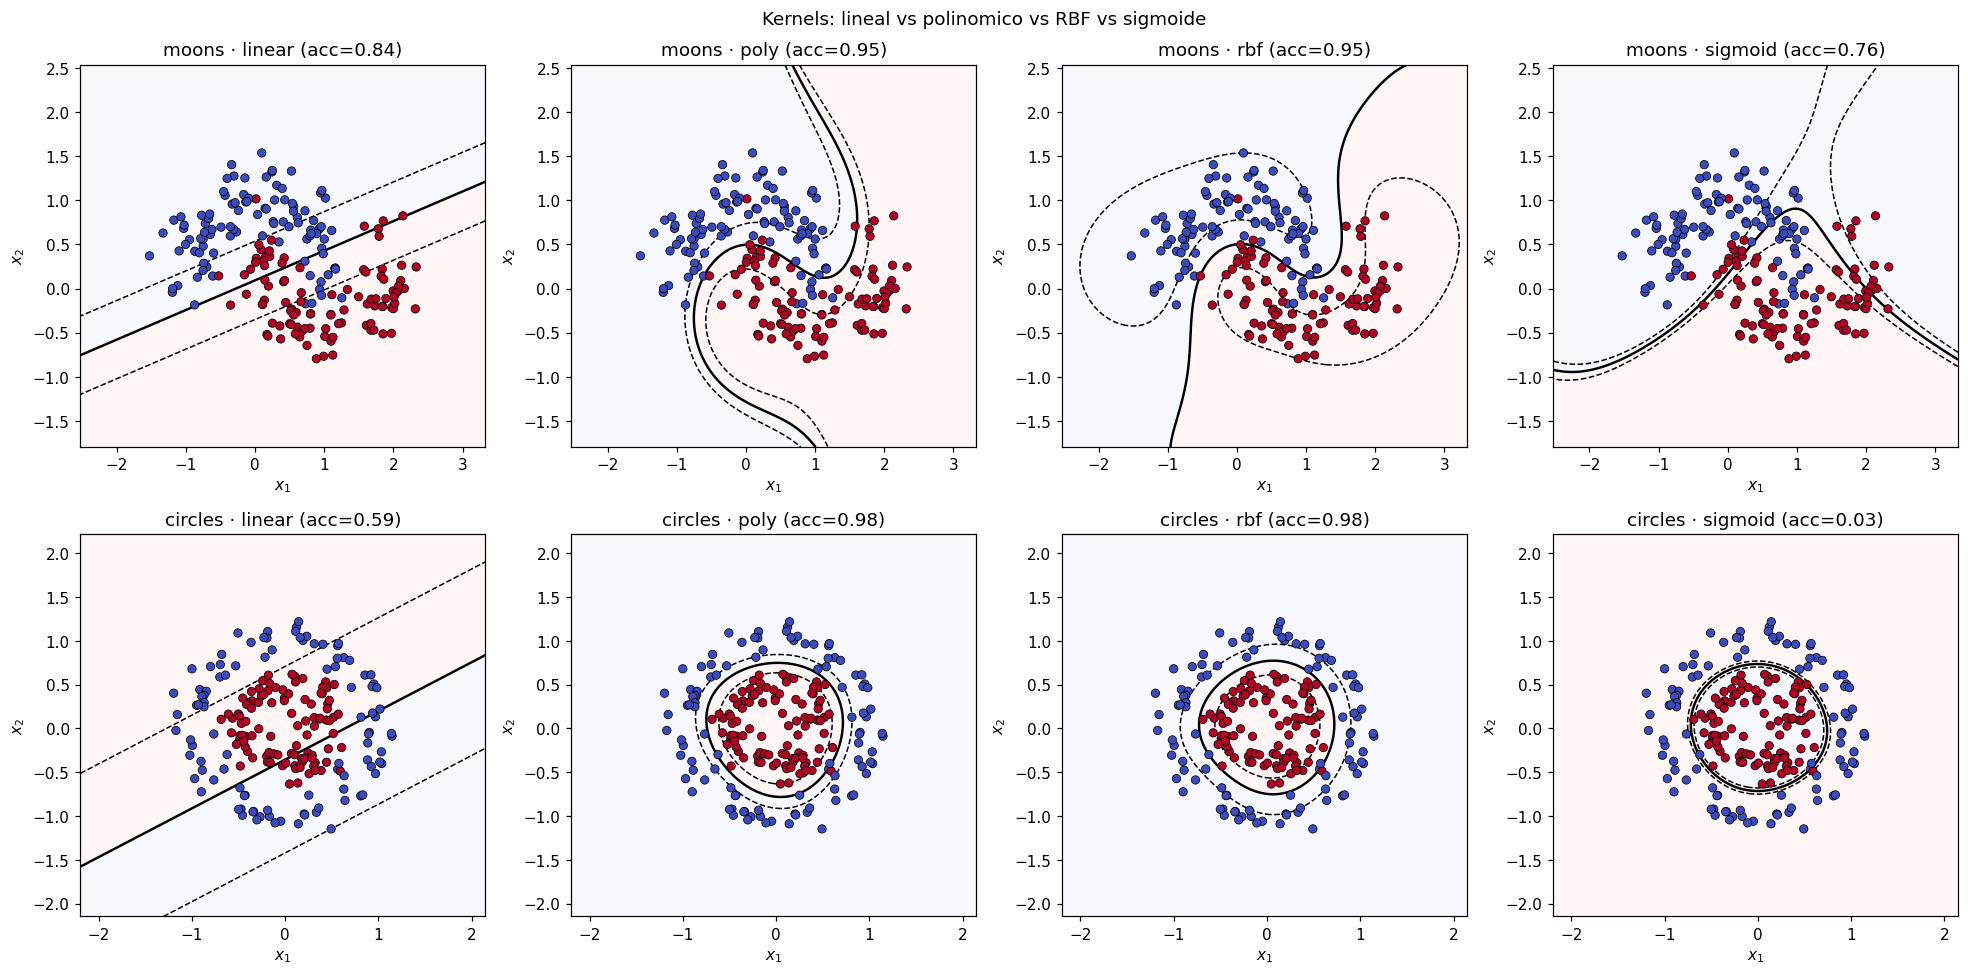

In [10]:
datasets = {
    "moons":   make_moons(n_samples=200, noise=0.22, random_state=RNG),
    "circles": make_circles(n_samples=200, noise=0.12, factor=0.45, random_state=RNG),
}
kernels = ["linear", "poly", "rbf", "sigmoid"]

fig, axes = plt.subplots(len(datasets), len(kernels), figsize=(18, 9))
for row, (name, (Xk, yk)) in enumerate(datasets.items()):
    for col, kern in enumerate(kernels):
        clf = make_pipeline(
            StandardScaler(),
            SVC(kernel=kern, C=1.0, gamma="scale", degree=3, coef0=1)
        ).fit(Xk, yk)
        acc = clf.score(Xk, yk)
        plot_svc_decision(clf, Xk, yk, ax=axes[row, col], support=False,
                          title=f"{name} · {kern} (acc={acc:.2f})")
plt.suptitle("Kernels: lineal vs polinomico vs RBF vs sigmoide")
plt.tight_layout(); plt.show()

**Tabla de kernels del informe**

| Kernel | $K(\mathbf{x},\mathbf{x}')$ | uso típico |
|---|---|---|
| Lineal | $\mathbf{x}\cdot\mathbf{x}'$ | datos separables / muchas *features* |
| Polinómico | $(\gamma\,\mathbf{x}\cdot\mathbf{x}'+r)^d$ | fronteras curvas de grado $d$ |
| RBF / Gauss | $\exp(-\gamma\|\mathbf{x}-\mathbf{x}'\|^2)$ | **opción por defecto** |
| Sigmoide | $\tanh(\gamma\,\mathbf{x}\cdot\mathbf{x}'+r)$ | similar a red neuronal |

El parámetro $\gamma$ del RBF controla el alcance: $\gamma$ alto → fronteras locales
(*overfitting*); $\gamma$ bajo → fronteras suaves.

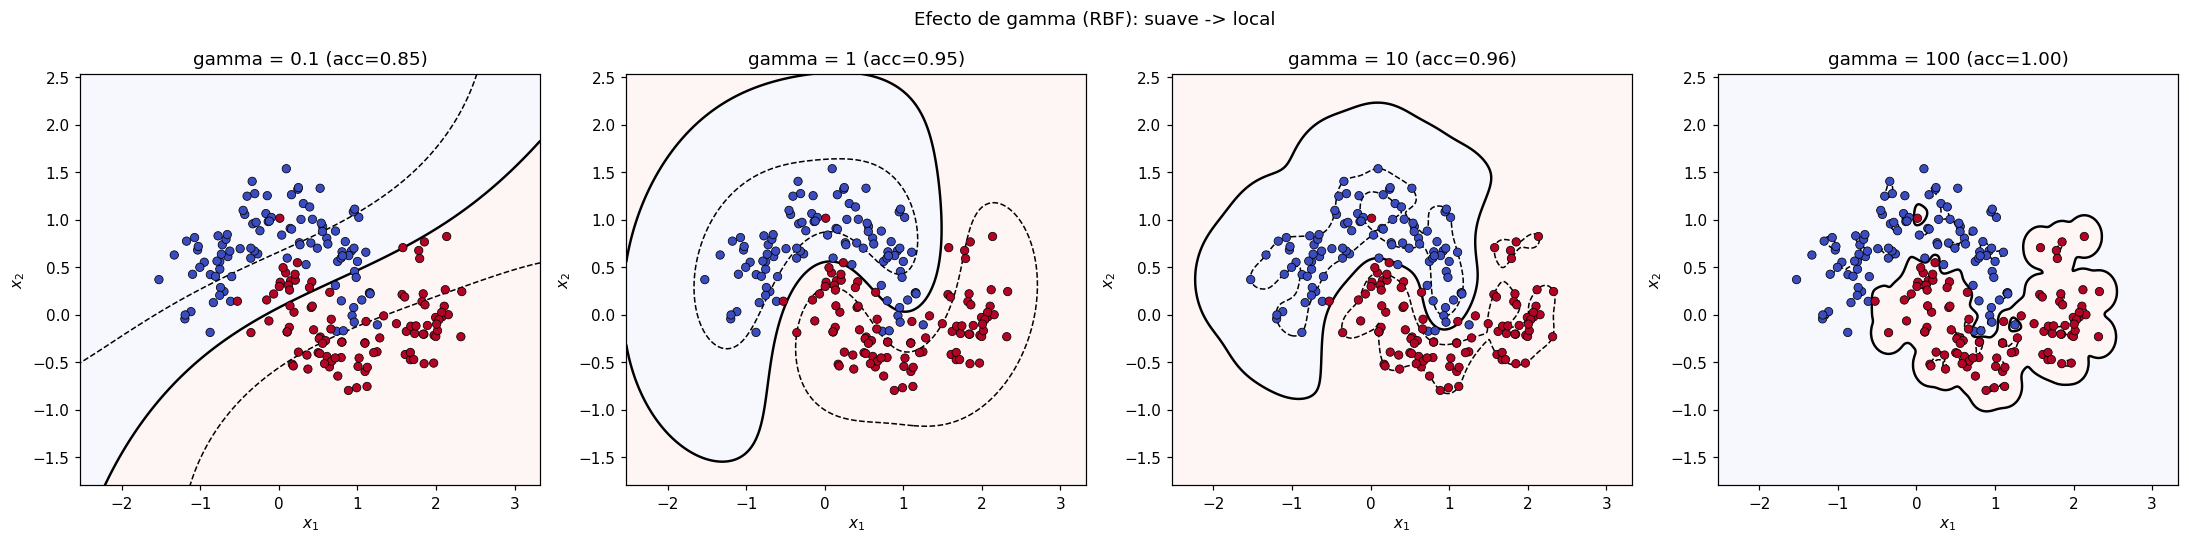

In [11]:
Xm, ym = datasets["moons"]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, g in zip(axes, [0.1, 1, 10, 100]):
    clf = SVC(kernel="rbf", C=1.0, gamma=g).fit(Xm, ym)
    plot_svc_decision(clf, Xm, ym, ax=ax, support=False,
                      title=f"gamma = {g} (acc={clf.score(Xm, ym):.2f})")
plt.suptitle("Efecto de gamma (RBF): suave -> local")
plt.tight_layout(); plt.show()

## 5. SVM para clasificación: multiclase y **el mejor modelo**

La SVM es binaria por naturaleza; para varias clases se combinan clasificadores
**one-vs-one** (por defecto en `libsvm`) o **one-vs-rest**. Usamos el dataset *iris*.

> **Buena práctica del informe:** la SVM es muy sensible a la escala → siempre
> `StandardScaler`, y los hiperparámetros se ajustan con **búsqueda en malla +
> validación cruzada** sobre $C$, $\gamma$ y el kernel. Esto es lo que hace que el
> modelo final sea robusto y "no falle".

In [12]:
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RNG, stratify=y)

# one-vs-one vs one-vs-rest (ambos sobre datos escalados)
for name, strat in [("one-vs-one", OneVsOneClassifier),
                    ("one-vs-rest", OneVsRestClassifier)]:
    clf = make_pipeline(StandardScaler(), strat(SVC(kernel="rbf", gamma="scale")))
    clf.fit(X_train, y_train)
    print(f"{name:12s} -> accuracy test = {clf.score(X_test, y_test):.3f}")

one-vs-one   -> accuracy test = 0.947
one-vs-rest  -> accuracy test = 0.947


### Búsqueda del mejor modelo con `GridSearchCV`

Validación cruzada estratificada sobre una malla de $C$, $\gamma$ y kernel. El
`Pipeline` garantiza que el escalado se ajuste **dentro** de cada *fold* (sin fuga
de datos).

In [13]:
pipe = Pipeline([("scaler", StandardScaler()), ("svc", SVC())])

param_grid = [
    {"svc__kernel": ["rbf"],
     "svc__C": [0.1, 1, 10, 100],
     "svc__gamma": ["scale", 0.01, 0.1, 1]},
    {"svc__kernel": ["linear"],
     "svc__C": [0.1, 1, 10, 100]},
    {"svc__kernel": ["poly"],
     "svc__C": [0.1, 1, 10],
     "svc__degree": [2, 3],
     "svc__gamma": ["scale"]},
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Mejores hiperparametros:", grid.best_params_)
print(f"Accuracy CV (train) : {grid.best_score_:.3f}")

Mejores hiperparametros: {'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
Accuracy CV (train) : 0.982


In [14]:
best = grid.best_estimator_
y_pred = best.predict(X_test)
print(f"Accuracy en TEST    : {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy en TEST    : 0.921

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



## 6. SVM para regresión (SVR)

En vez de separar clases, la SVR ajusta una función dentro de un **"tubo" de ancho
$\varepsilon$**. Los puntos **dentro** del tubo no se penalizan ($\alpha_i=0$, no son
vectores de soporte); sólo los que tocan o salen del borde construyen la función.
Esto reproduce el §3.4 del informe aplicado a regresión.

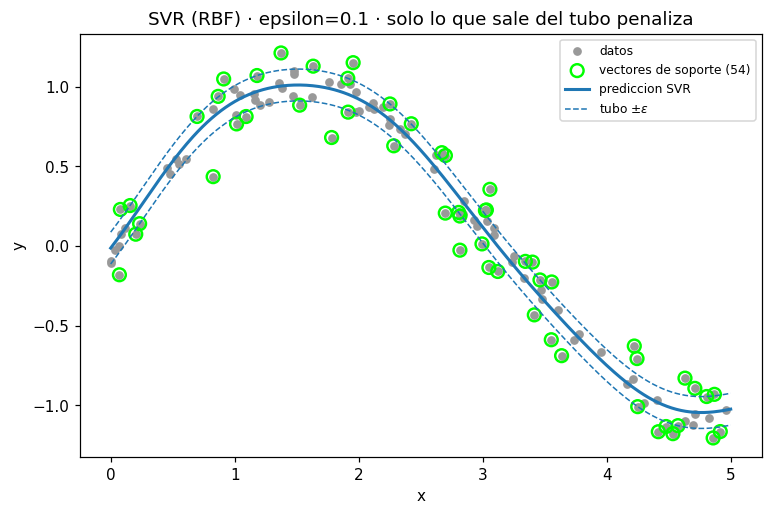

Puntos totales        : 120
Vectores de soporte   : 54  (resto cae dentro del tubo)
RMSE                  : 0.1216


In [15]:
# senal no lineal con ruido
X_reg = np.sort(5 * np.random.rand(120, 1), axis=0)
y_reg = np.sin(X_reg).ravel() + 0.12 * np.random.randn(X_reg.shape[0])

eps = 0.1
svr = SVR(kernel="rbf", C=100, gamma=0.5, epsilon=eps).fit(X_reg, y_reg)

xx = np.linspace(0, 5, 400).reshape(-1, 1)
yy = svr.predict(xx)
sv_idx = svr.support_                       # indices de los vectores de soporte

plt.figure(figsize=(8, 5))
plt.scatter(X_reg, y_reg, s=22, c="0.6", label="datos")
plt.scatter(X_reg[sv_idx], y_reg[sv_idx], s=70, facecolors="none",
            edgecolors="lime", linewidths=1.6,
            label=f"vectores de soporte ({len(sv_idx)})")
plt.plot(xx, yy, "C0", lw=2, label="prediccion SVR")
plt.plot(xx, yy + eps, "C0--", lw=1, label=r"tubo $\pm\varepsilon$")
plt.plot(xx, yy - eps, "C0--", lw=1)
plt.title(f"SVR (RBF) · epsilon={eps} · solo lo que sale del tubo penaliza")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(fontsize=8); plt.show()

print(f"Puntos totales        : {len(X_reg)}")
print(f"Vectores de soporte   : {len(sv_idx)}  (resto cae dentro del tubo)")
print(f"RMSE                  : {mean_squared_error(y_reg, svr.predict(X_reg))**0.5:.4f}")

## 7. Conclusiones

- Verificamos **numéricamente** el proceso interno: sólo las muestras con $\alpha_i>0$
  son vectores de soporte, distinguimos SV **libres** ($0<\alpha<C$) y **acotados**
  ($\alpha=C$), y reconstruimos $\mathbf{w}$, $b$ y $f(\mathbf{x})$ exclusivamente a
  partir de ellos (coincidencia exacta con `scikit-learn`).
- El **kernel trick** resuelve problemas no lineales; $\gamma$ y $C$ controlan el
  equilibrio sesgo–varianza.
- Para que el modelo final **no falle**: `StandardScaler` siempre, `Pipeline` para
  evitar fuga de datos, y `GridSearchCV` + validación cruzada estratificada para
  elegir los mejores hiperparámetros.
- **SVR** aplica la misma idea con el tubo $\varepsilon$.